# Supplementary Figure 7: common search databases

Healthy-stool identity retention when acquisitions are searched against one common FASTA, separately or jointly (a);
participant-level changes in PREDICT and CapScan with a common FASTA (b); and microbial protein-group precision
between technical (c) and preparation (d) replicate pairs. Peptide counts in a and b are 9-50 residues. The v30
figure is drawn on one canvas in house style; the producer is run unchanged alongside it and every plotted array is
compared exactly. Each panel is cut from the render at its axes box for display.

Run from the repository root: `python paper.py build SFig07`.

In [1]:
from pathlib import Path
import sys
UNIT = Path.cwd()                 # the notebook runs with its own directory as cwd
REPO = UNIT.parents[1]
sys.path[:0] = [str(REPO), str(UNIT)]
SD = REPO / "source_data" / UNIT.name
OUT = REPO / "build" / UNIT.name   # rendered panels; gitignored
OUT.mkdir(parents=True, exist_ok=True)
from style import fl_style as fl
import panels
fl.init()
from IPython.display import Image, display

## Panel a

Original 9-50-residue peptide identities retained per acquisition by five search designs, relative to the
acquisition-specific searches. Supports v30 Results (v30f text line 57): "Both retained about 94% of the original
peptide identities (Supplementary Fig. 7a and Source Data)". n = 58 acquisitions per column (one healthy-stool study).
Test: none; medians are descriptive.

  [style] SupplementaryFigure7: 0 label(s) raised to 5 pt, 4 capped to 7 pt, 0 tick axis/axes clamped, 0 line(s) raised to 1 pt


<repo>/figures/SFig07/panels.py:782: UserWarning: SupplementaryFigure7.pdf is 160.00 mm wide, not 88 or 180 mm (nearest 180). compose.py will refuse it. If it is a near miss, the cause is almost always a bbox that cropped the canvas -- REDRAW at the placed width; do not scale and do not pad.
  pdf, png = fl.save(fig, out / "SupplementaryFigure7", formats=("pdf", "png"))


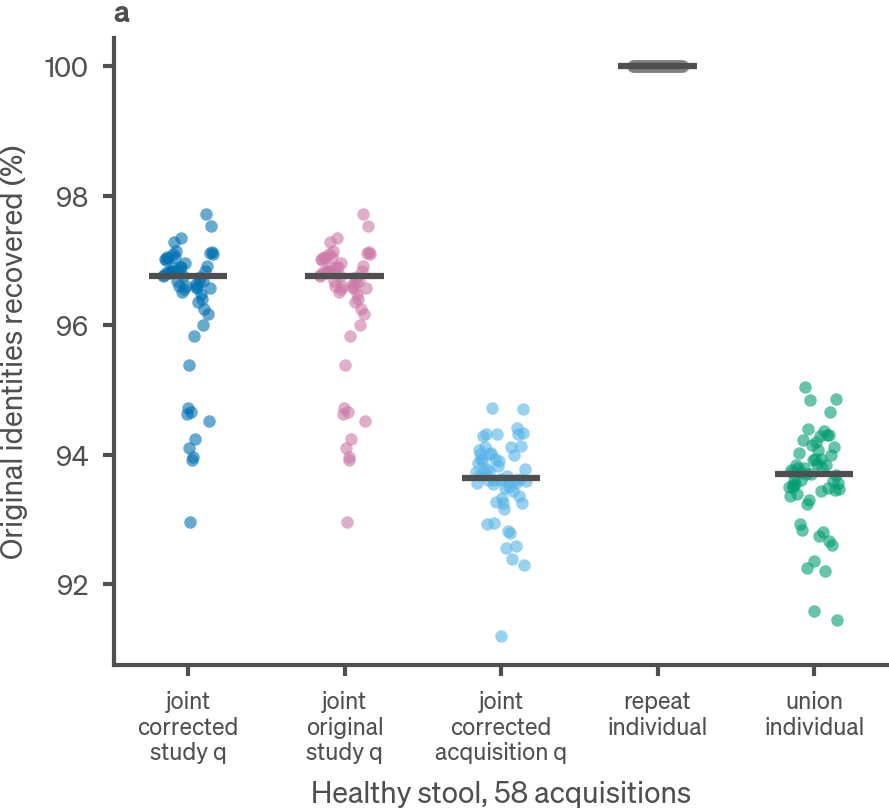

In [2]:
res = panels.render_v30(SD, OUT)      # draws a-d on one canvas and checks values against the producer
panels.crop(res["png"], res["axes_bbox_px"]["a"], OUT / "panel_a.png")
display(Image(filename=str(OUT / "panel_a.png"), width=420))

## Panel b

Participant-level percentage change of accepted 9-50-residue peptides (x) and directLFQ protein groups (y) when each
acquisition is searched against the common study FASTA instead of its own FASTA. Acquisitions are averaged within
specimen, then specimens within participant (upstream). Supports the legend (v30f line 234): "PREDICT (93 patients)
and CapScan (15 participants)" and Methods (v30f line 142): "median participant-level increases of 2.4% in 93 PREDICT
and 3.6% in fifteen CapScan participants". n = 93 PREDICT patients and 15 CapScan participants. Test: none.

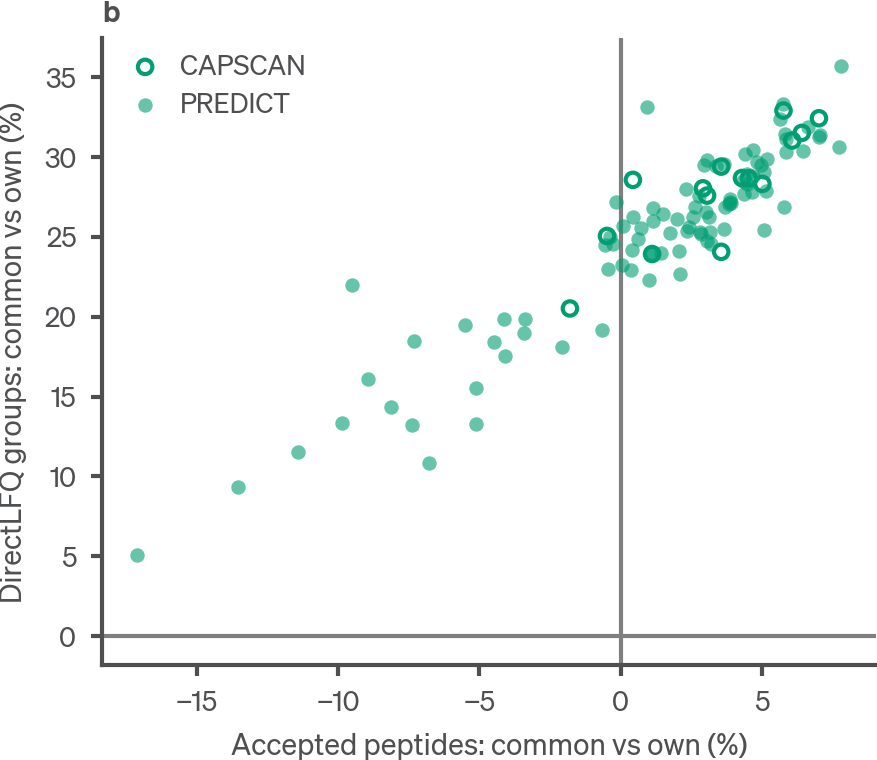

In [3]:
panels.crop(res["png"], res["axes_bbox_px"]["b"], OUT / "panel_b.png")
display(Image(filename=str(OUT / "panel_b.png"), width=420))

## Panel c

Median microbial protein-group pair CV for each pair of the 12 technical replicates, under own-row and matched-row
definitions. Supports Supplementary Methods 7 (v30f line 395): "reduced median pairwise CV between technical
replicates from 20.1% to 15.2%". n = 66 acquisition pairs (dependent). Test: none; medians are descriptive.

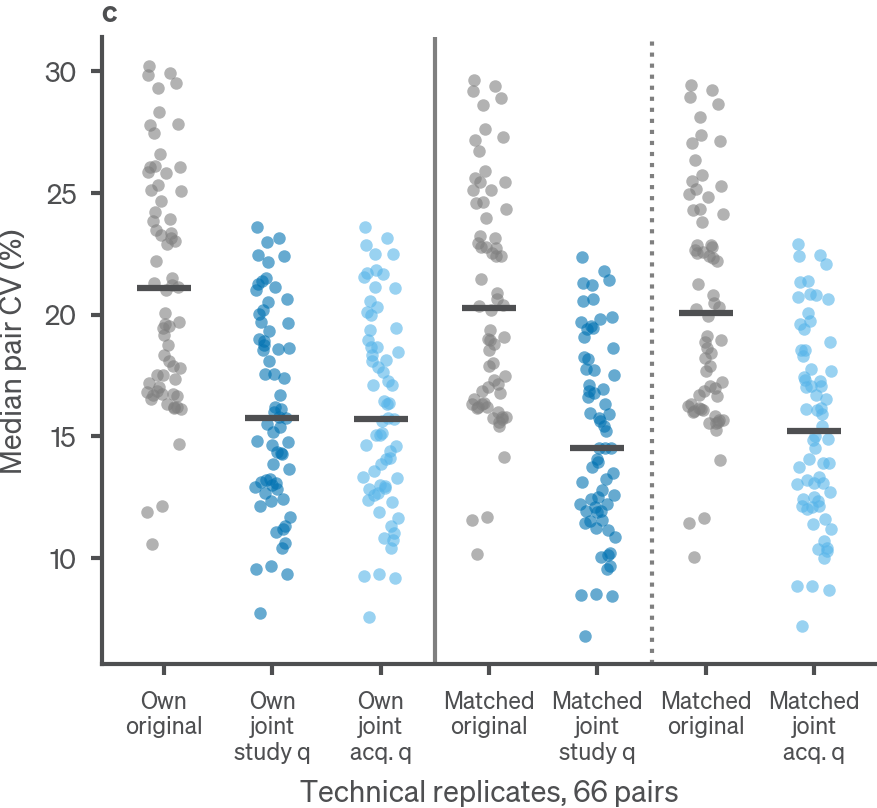

In [4]:
panels.crop(res["png"], res["axes_bbox_px"]["c"], OUT / "panel_c.png")
display(Image(filename=str(OUT / "panel_c.png"), width=420))

## Panel d

As panel c for the 15 independently prepared replicates. Supports v30f line 395: "CV increased from 32.9% to 35.1%".
n = 105 acquisition pairs (dependent). Test: none.

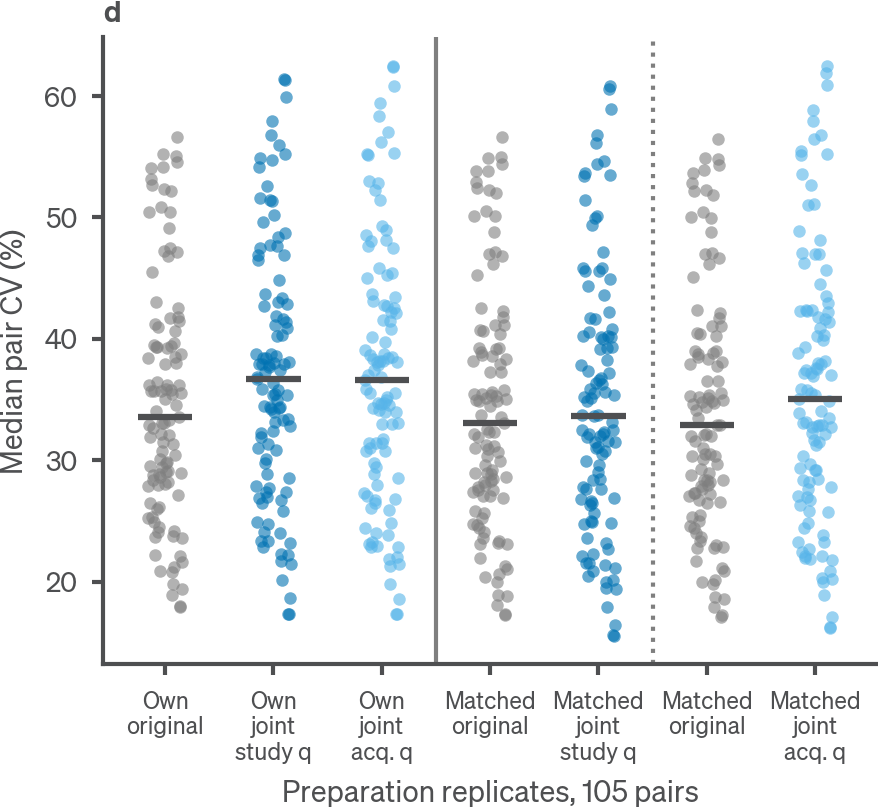

In [5]:
panels.crop(res["png"], res["axes_bbox_px"]["d"], OUT / "panel_d.png")
display(Image(filename=str(OUT / "panel_d.png"), width=420))

## Checks and numbers

Pixel checks of the v30 composite (PNG at 300 dpi and PDF rasterised at 300 dpi) against the published v30 render,
the restyle-versus-producer value checks, agreement of recomputed summaries with the upstream summary tables, and
every number in `NUMBERS.tsv` in file order.

In [6]:
from tools.check_pixels import compare
if not fl._HAVE_STYLE:
    print("pixel checks SKIPPED: fonts absent")
else:
    CH = UNIT / "checks"
    for name, new, exp, kw in [("SFig07_v30", res["png"], "SFig07_v30.png", {}),
                               ("SFig07_v30_pdf", res["pdf"], "SFig07_v30.pdf", {"dpi": 300})]:
        r = compare(new, UNIT / "expected" / exp, CH / name, **kw)
        print(name, r["verdict"], r.get("differing_pixels"), r.get("max_channel_difference"))
T = panels.load(SD)
checks = res["checks"] + panels.consistency(T)
print(sum(c["passed"] for c in checks), "of", len(checks), "value checks passed")
assert all(c["passed"] for c in checks)
for key, value in panels.all_numbers(T):
    print(key, "\t", repr(value))

SFig07_v30 IDENTICAL 0 0


SFig07_v30_pdf IDENTICAL 0 0
95 of 95 value checks passed
R56 union_individual gain % 	 11.372375880158048
R56 joint_fileq gain % 	 11.618239886025217
R56 union_individual retention % 	 93.70441065185946
R56 joint_fileq retention % 	 93.64980444713049
R56 complete features original 	 10493
R56 complete features joint_fileq 	 13149
R56 joint_corrected gain % 	 34.22356228866281
M141 distinct peptides union_individual gain % 	 4.4070221955671895
M141 PREDICT median participant peptide change % 	 2.4223268501881945
M141 PREDICT participants 	 93
M141 CapScan median participant peptide change % 	 3.5535273152426106
M141 CapScan participants 	 15
SF7 legend PREDICT participants 	 93
SF7 legend CapScan participants 	 15
SF7 legend technical pairs 	 66
SF7 legend preparation pairs 	 105
M394 acq-q technical CV original 	 20.08222739823691
M394 acq-q technical CV joint 	 15.20662680089535
M394 acq-q technical r original 	 0.8291595091184634
M394 acq-q technical r joint 	 0.8670148297488702
M39